[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/hentablihamza/attention-explained/blob/main/notebooks/06_self_attention.ipynb)

# 06 · Self-Attention: a Sentence Looking at Itself

*Attention, Explained · Hamza Hentabli, Ph.D. · ~30 min*

So far, queries came from one place and keys from another. In **self-attention** a sentence attends to **itself**: every word asks every other word *"are you relevant to me?"*. In this notebook we build self-attention, then train a tiny model to solve the famous *"…because **it** was too tired"* puzzle and watch, in the real learned weights, how attention resolves *it*.

**Learning objectives.** By the end of this notebook you will be able to:

- explain **self-attention** and how it creates **contextual** word vectors
- implement a self-attention layer in NumPy
- train a tiny model whose output *is* an attention distribution, on a toy **coreference** task
- read the learned weights and explain the **two hops** used to resolve *it*

In [1]:
# Setup: on Google Colab this installs anything missing and clones the repo so the
# shared `attn_utils` helper is available. Running locally, install requirements.txt
# once and this cell just locates the files. No notebook needs the network after this.
import os, sys, subprocess

IN_COLAB = "google.colab" in sys.modules
OFFLINE = os.environ.get("ATTN_OFFLINE", "0") == "1"   # CI sets this; everything is computed locally
if IN_COLAB:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                    "numpy", "torch", "matplotlib", "scikit-learn"], check=True)
    if not os.path.isdir("attention-explained"):
        subprocess.run(["git", "clone", "-q", "--depth", "1",
                        "https://github.com/hentablihamza/attention-explained.git"], check=True)
    ROOT = "attention-explained"
else:
    ROOT = ".." if os.path.exists("../attn_utils.py") else "."
if ROOT not in sys.path:
    sys.path.insert(0, ROOT)

import numpy as np
import matplotlib.pyplot as plt
import attn_utils as au

au.set_docs_dir(os.path.join(ROOT, "docs"))
au.set_seed(0)
np.set_printoptions(precision=3, suppress=True)
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})
print("Colab:", IN_COLAB, "| offline:", OFFLINE, "| numpy", np.__version__)


Colab: False | offline: True | numpy 2.4.6


## 1. Self-attention: queries, keys and values from the *same* sentence

In Notebook 01 the decoder attended to the *encoder* (cross-attention). In **self-attention** every token of one sentence produces a query, a key and a value, and every token attends to **every token of the same sentence**, itself included:

$$Z = \text{softmax}\!\left(\frac{(XW_Q)(XW_K)^\top}{\sqrt{d_k}}\right) XW_V$$

The output row $z_i$ is a new vector for token $i$ that has **mixed in information from the tokens it attended to**. That is how a word's representation becomes *contextual*: the vector for *bank* can end up different in *river bank* and *bank account*.

Here is a minimal self-attention layer in NumPy.

In [2]:
class SelfAttention:
    def __init__(self, d_model, d_k, seed=0):
        rng = np.random.default_rng(seed)
        s = 1 / np.sqrt(d_model)
        self.WQ, self.WK, self.WV = (rng.normal(scale=s, size=(d_model, d_k)) for _ in range(3))
    def __call__(self, X, mask=None):
        return au.scaled_dot_product_attention(X @ self.WQ, X @ self.WK, X @ self.WV, mask=mask)

X_demo = np.random.default_rng(1).normal(size=(5, 8))     # 5 tokens, d_model = 8
Z_demo, A_demo = SelfAttention(8, 4)(X_demo)
print("input", X_demo.shape, "-> output", Z_demo.shape, "| weights", A_demo.shape)

input (5, 8) -> output (5, 4) | weights (5, 5)


## 2. The classic puzzle: what does *it* refer to?

> The animal didn't cross the street because **it** was too **tired**.
> The animal didn't cross the street because **it** was too **wide**.

Only one word changes, yet *it* flips from *animal* to *street*. Two things make this hard:

1. The deciding word (*tired* / *wide*) comes **after** *it* — the model must look **forward** as well as back.
2. Resolving *it* needs **two hops**: first find out *what* is being said about it (tired → something alive; wide → something physical), then find the noun that fits.

Self-attention handles both: every token sees every other token, and stacking layers gives multiple hops. Let's **train** a tiny model to do it and look inside.

### A toy coreference dataset

Sentences follow the template *"the ⟨animal⟩ didn't cross the ⟨place⟩ because it was too ⟨adjective⟩"*. Adjectives that describe creatures (*tired, scared, …*) mean *it* = the animal; adjectives that describe places (*wide, busy, …*) mean *it* = the place. The model's job: **point at the word *it* refers to.**

To check the model *generalises* instead of memorising, we hold out a set of (animal, place) pairs that never appear in training.

In [3]:
import itertools, random
import torch
import torch.nn as nn
import torch.nn.functional as F
torch.set_num_threads(4)

animals = ["animal", "dog", "cat", "horse", "cow", "fox", "rabbit", "deer"]
places  = ["street", "road", "river", "bridge", "field", "highway", "canal", "path"]
adj_creature = ["tired", "scared", "lazy", "slow", "sleepy"]
adj_place    = ["wide", "busy", "long", "crowded", "flooded"]
TEMPLATE = "the {a} didn't cross the {p} because it was too {j}"
POS_ANIMAL, POS_PLACE, POS_IT, POS_ADJ = 1, 5, 7, 10

random.seed(0)
pairs = list(itertools.product(animals, places))
random.shuffle(pairs)
test_pairs, train_pairs = pairs[:12], pairs[12:]       # 12 unseen (animal, place) combinations

def make(pair_list, n):
    sents, targets = [], []
    for _ in range(n):
        a, p = random.choice(pair_list)
        if random.random() < 0.5:
            j, tgt = random.choice(adj_creature), POS_ANIMAL
        else:
            j, tgt = random.choice(adj_place), POS_PLACE
        sents.append(TEMPLATE.format(a=a, p=p, j=j).split()); targets.append(tgt)
    return sents, targets

words = sorted({w for w in TEMPLATE.split() if "{" not in w} | set(animals + places + adj_creature + adj_place))
w2i = {w: i for i, w in enumerate(words)}
encode = lambda sents: torch.tensor([[w2i[w] for w in s] for s in sents])
example, tgt = make(train_pairs, 1)
print(" ".join(example[0]), "->  it =", example[0][tgt[0]])
print(f"vocabulary: {len(words)} words | train pairs: {len(train_pairs)} | held-out pairs: {len(test_pairs)}")

the cow didn't cross the field because it was too crowded ->  it = field
vocabulary: 33 words | train pairs: 52 | held-out pairs: 12


### The model: one self-attention layer + a "pointer" attention

1. **Embeddings + learned position vectors** (positions are explained in Notebook 08).
2. **One self-attention layer** (with a residual connection and layer norm, explained in Notebook 09). This is where *it* can gather information from other words.
3. A **pointer**: one more attention step where the query is the *it* token and the keys are all tokens. Its softmax **is** the prediction: the weight on each word = probability that *it* refers to that word.

So the answer is literally an attention distribution. About 7,000 parameters.

In [4]:
D, L = 32, len(TEMPLATE.split())

class TinyCoref(nn.Module):
    def __init__(self):
        super().__init__()
        self.emb = nn.Embedding(len(words), D)
        self.pos = nn.Parameter(torch.randn(L, D) * 0.1)
        self.q, self.k, self.v = nn.Linear(D, D), nn.Linear(D, D), nn.Linear(D, D)
        self.norm = nn.LayerNorm(D)
        self.ptr_q, self.ptr_k = nn.Linear(D, D), nn.Linear(D, D)

    def forward(self, x, block=None):
        h = self.emb(x) + self.pos                                            # (B, L, D)
        scores = self.q(h) @ self.k(h).transpose(1, 2) / D ** 0.5
        if block is not None:                                                 # optional (L, L) bool mask, used for ablations
            scores = scores.masked_fill(block, float("-inf"))
        attn = scores.softmax(-1)                                              # self-attention weights (B, L, L)
        h = self.norm(h + attn @ self.v(h))                                    # residual + norm
        ptr = (self.ptr_q(h[:, POS_IT:POS_IT + 1]) @ self.ptr_k(h).transpose(1, 2) / D ** 0.5).squeeze(1)
        return ptr, attn                                                       # pointer logits (B, L)

au.set_seed(0)
model = TinyCoref()
print("parameters:", sum(p.numel() for p in model.parameters()))

parameters: 6752


Before training, where does *it* point? (Random weights → roughly arbitrary.)

In [5]:
s_tired = TEMPLATE.format(a="animal", p="street", j="tired").split()
s_wide  = TEMPLATE.format(a="animal", p="street", j="wide").split()
with torch.no_grad():
    ptr0, _ = model(encode([s_tired, s_wide]))
P0 = ptr0.softmax(-1).numpy()
for s, p in zip((s_tired, s_wide), P0):
    print(f"...too {s[-1]:6s} -> it points to '{s[p.argmax()]}' (p = {p.max():.2f})")

...too tired  -> it points to 'tired' (p = 0.14)
...too wide   -> it points to 'too' (p = 0.14)


In [6]:
opt = torch.optim.Adam(model.parameters(), lr=1e-2)
losses = []
for step in range(300):
    sents, targets = make(train_pairs, 64)
    logits, _ = model(encode(sents))
    loss = F.cross_entropy(logits, torch.tensor(targets))
    opt.zero_grad(); loss.backward(); opt.step()
    losses.append(loss.item())
    if step % 50 == 0 or step == 299:
        print(f"step {step:3d}  loss {loss.item():.4f}")

random.seed(1)
test_s, test_t = make(test_pairs, 1000)
with torch.no_grad():
    logits, _ = model(encode(test_s))
acc = (logits.argmax(-1) == torch.tensor(test_t)).float().mean().item()
print(f"\naccuracy on 1000 sentences built from the 12 HELD-OUT (animal, place) pairs: {acc:.3f}")

step   0  loss 2.3513
step  50  loss 0.0005
step 100  loss 0.0000


step 150  loss 0.0000
step 200  loss 0.0000
step 250  loss 0.0000


step 299  loss 0.0000

accuracy on 1000 sentences built from the 12 HELD-OUT (animal, place) pairs: 1.000


## 3. Look inside: two hops of attention

...too tired: 'it' -> 'animal' (p = 1.000) | weight on the adjective from 'it' 0.01, from 'animal' 1.00, from 'street' 0.00
...too wide : 'it' -> 'street' (p = 1.000) | weight on the adjective from 'it' 0.02, from 'animal' 0.98, from 'street' 0.00


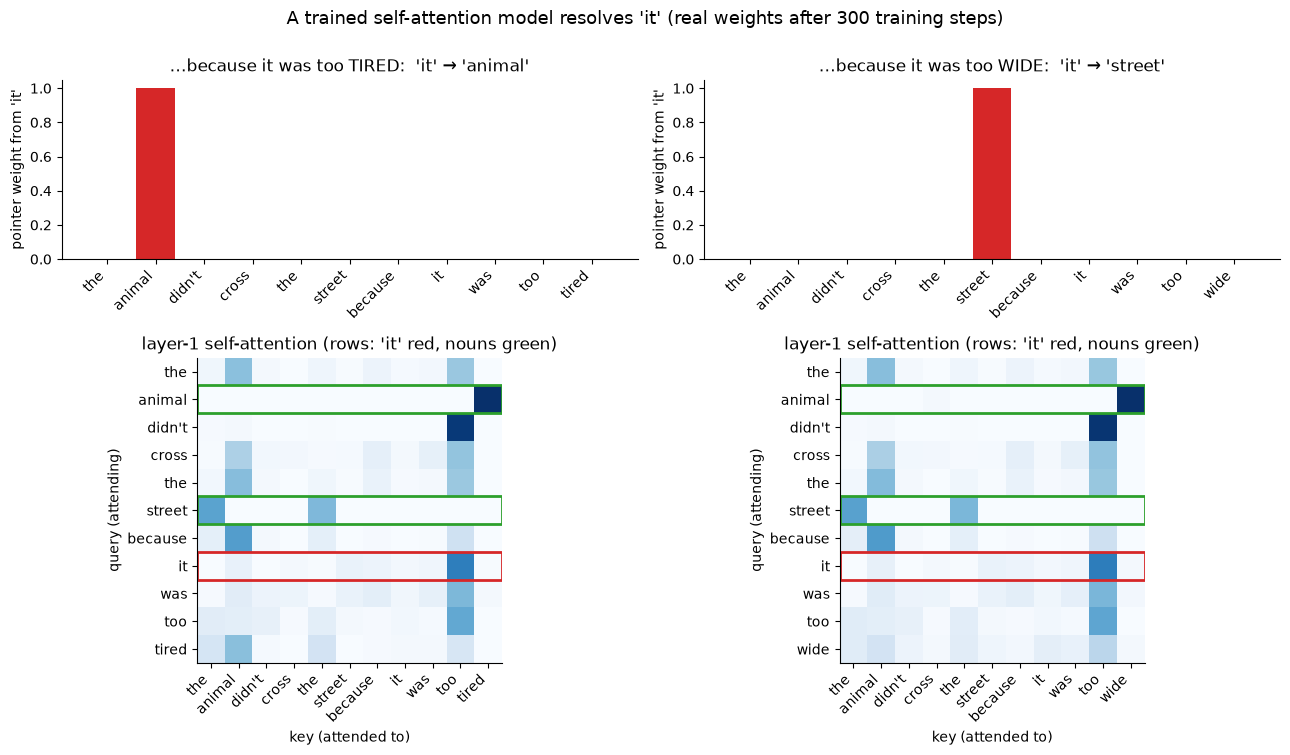

In [7]:
with torch.no_grad():
    ptr, attn = model(encode([s_tired, s_wide]))
P = ptr.softmax(-1).numpy(); Att = attn.numpy()

for s, p, a in zip((s_tired, s_wide), P, Att):
    print(f"...too {s[-1]:5s}: 'it' -> '{s[p.argmax()]}' (p = {p.max():.3f}) | weight on the adjective from "
          f"'it' {a[POS_IT, POS_ADJ]:.2f}, from '{s[POS_ANIMAL]}' {a[POS_ANIMAL, POS_ADJ]:.2f}, from '{s[POS_PLACE]}' {a[POS_PLACE, POS_ADJ]:.2f}")

fig, axes = plt.subplots(2, 2, figsize=(13, 7.5), gridspec_kw={"height_ratios": [1, 1.7]})
for col, (s, p, a) in enumerate(zip((s_tired, s_wide), P, Att)):
    ax = axes[0, col]
    colors = ["tab:red" if i == p.argmax() else "tab:blue" for i in range(L)]
    ax.bar(range(L), p, color=colors)
    ax.set_xticks(range(L)); ax.set_xticklabels(s, rotation=45, ha="right"); ax.set_ylim(0, 1.05)
    ax.set_title(f"…because it was too {s[-1].upper()}:  'it' → '{s[p.argmax()]}'")
    ax.set_ylabel("pointer weight from 'it'")
    au.plot_attention(a, s, s, ax=axes[1, col], annotate=False, title="layer-1 self-attention (rows: 'it' red, nouns green)")
    axes[1, col].add_patch(plt.Rectangle((-0.5, POS_IT - 0.5), L, 1, fill=False, ec="tab:red", lw=2))
    for r in (POS_ANIMAL, POS_PLACE):
        axes[1, col].add_patch(plt.Rectangle((-0.5, r - 0.5), L, 1, fill=False, ec="tab:green", lw=2))
fig.suptitle("A trained self-attention model resolves 'it' (real weights after 300 training steps)", y=1.0, fontsize=13)
plt.tight_layout()
au.save_fig(fig, "06_self_attention_it.png")
plt.show()

### Which connection carries the decisive clue? An ablation

Attention weights tell us where information *can* flow, not how much each flow *matters*. A more direct test is an **ablation**: forbid one connection (set its score to −∞ before the softmax) and see whether the model still gets the answer right on the held-out sentences.

In [8]:
def heldout_accuracy(block=None):
    with torch.no_grad():
        logits, attn = model(encode(test_s), block=block)
    return (logits.argmax(-1) == torch.tensor(test_t)).float().mean().item(), attn

acc_full, attn_all = heldout_accuracy()
w_it = attn_all[:, POS_IT].mean(0).numpy()
print("average layer-1 weight FROM 'it' over the held-out set (uniform would be 1/11 = 0.091):")
print("  " + "  ".join(f"{w}:{a:.2f}" for w, a in zip(s_tired, w_it)))
mean_attn = attn_all.mean(0).numpy()
print(f"average weight on the adjective FROM the animal noun: {mean_attn[POS_ANIMAL, POS_ADJ]:.2f}, "
      f"FROM the place noun: {mean_attn[POS_PLACE, POS_ADJ]:.2f}")

print(f"\nheld-out accuracy, nothing blocked                      : {acc_full:.3f}")
ablations = {}
for name, cols, rows in [("'it' -> adjective", [POS_ADJ], [POS_IT]),
                         ("'it' -> 'too'", [9], [POS_IT]),
                         ("nouns -> adjective", [POS_ADJ], [POS_ANIMAL, POS_PLACE]),
                         ("everyone -> adjective", [POS_ADJ], list(range(L)))]:
    block = torch.zeros(L, L, dtype=torch.bool)
    for r in rows:
        if r not in cols:            # a token may always keep looking at itself
            block[r, cols] = True
    ablations[name] = heldout_accuracy(block)[0]
    print(f"held-out accuracy, block {name:24s}       : {ablations[name]:.3f}")

average layer-1 weight FROM 'it' over the held-out set (uniform would be 1/11 = 0.091):
  the:0.00  animal:0.07  didn't:0.00  cross:0.01  the:0.00  street:0.06  because:0.05  it:0.02  was:0.03  too:0.56  tired:0.19
average weight on the adjective FROM the animal noun: 0.86, FROM the place noun: 0.02

held-out accuracy, nothing blocked                      : 1.000
held-out accuracy, block 'it' -> adjective              : 0.996
held-out accuracy, block 'it' -> 'too'                  : 1.000
held-out accuracy, block nouns -> adjective             : 0.492
held-out accuracy, block everyone -> adjective          : 0.492


### What the experiment shows

Read the printed numbers from your run together with the figure:

- **The pointer works.** On sentences built from (animal, place) pairs the model never saw, *it* points to the right noun — *animal* for *tired*, *street* for *wide* — and the decision hinges on a word that comes **after** *it*. Self-attention reaches any position in one step, forwards or backwards.
- **The obvious story is not the true story.** You might expect *it* to look at the adjective in layer 1 and then go find the noun. The heatmap shows *it* puts most of its weight elsewhere (on *too* in our run), and blocking *it* → adjective barely changes accuracy.
- **The ablation finds the real route.** Blocking **everyone → adjective** drops accuracy to about chance (0.5), so the adjective *is* essential. Blocking only the **nouns → adjective** connections has exactly the same effect, which shows where it flows: in layer 1 the **animal noun reads the adjective** (its green row is bright on the last column, ≈0.86 on average in our run) while the place noun ignores it. So the animal's key ends up saying *"the clue fits me"* or *"it doesn't"*, and *it*'s pointer query picks the animal when its key lights up and the place otherwise.

That is still two hops of attention, just routed differently than a human would draw it. And it is the most important lesson about attention maps: **a heatmap shows where weight goes; only an intervention (ablation) shows what the model actually needs.** Large models such as BERT learn heads that perform coreference on real text (Clark et al., 2019, *"What Does BERT Look At?"*), and interpretability research uses exactly these ablation tools to check such claims.

## Key takeaways

- In **self-attention**, every token is a query, a key and a value, and every token can look at every other — forwards and backwards.
- Each output is a **context-dependent** version of the token.
- Stacking attention steps gives **multi-hop reasoning**: gather a clue, then use it to find the answer.

### ✏️ Exercise 1

Run the trained model on `"the cow didn't cross the river because it was too sleepy"` and `"... too flooded"`. Where does `it` point?

<details>
<summary><b>Show solution</b></summary>

```python
for j in ("sleepy", "flooded"):
    s = TEMPLATE.format(a="cow", p="river", j=j).split()
    with torch.no_grad():
        p, _ = model(encode([s]))
    print(j, "->", s[p.argmax().item()])
```



</details>

### ✏️ Exercise 2

Plot the training loss curve stored in `losses` with a log-scale y-axis.

<details>
<summary><b>Show solution</b></summary>

```python
plt.plot(losses); plt.yscale("log"); plt.xlabel("step"); plt.ylabel("loss"); plt.show()
```



</details>

### ✏️ Exercise 3

Swap the adjective lists' meaning ("tired" → place, "wide" → animal) is not possible to test without retraining. Instead, measure how much pointer probability goes to the **right** noun averaged over the 1000 held-out sentences.

<details>
<summary><b>Show solution</b></summary>

```python
with torch.no_grad():
    logits, _ = model(encode(test_s))
probs = logits.softmax(-1)
print(probs[torch.arange(len(test_t)), torch.tensor(test_t)].mean().item())
```



</details>